In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import scripts.extract_dataset as ed

In [4]:
# Read in the dataset
iclr2025v2 = pd.read_parquet("data/master.parquet")
iclr2025v2 = iclr2025v2[
    (iclr2025v2["authors"] != "Anonymous") &
    (iclr2025v2["year"] > 2020)
]

iclr2025v2.head()

,paper_idx,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels,n_authors,last_author,last_author_id,has_author_ids,decision_group,accepted,mean_score,embedding
5637,5637,2021,--GJkm7nt0,Enhancing Visual Representations for Efficient...,"We propose ENVISE, an online distillation fra...","Shashanka Venkataramanan, Bruce W McIntosh, Ab...","~Shashanka_Venkataramanan1, ~Bruce_W_McIntosh1...",Reject,"[4, 5, 5, 4]",[],unlabeled,3,Abhijit Mahalanobis,~Abhijit_Mahalanobis1,True,reject,False,4.500000,"[-0.048169, 0.060541, -0.020332, 0.1288, -0.04..."
5638,5638,2021,--gvHfE3Xf5,Meta-Learning of Structured Task Distributions...,"In recent years, meta-learning, in which a mod...","Sreejan Kumar, Ishita Dasgupta, Jonathan Cohen...","~Sreejan_Kumar1, ~Ishita_Dasgupta1, ~Jonathan_...",Accept (Poster),"[6, 6, 7, 7]","[meta-learning, human cognition, reinforcement...",meta learning,5,Thomas Griffiths,~Thomas_Griffiths1,True,accept,True,6.500000,"[0.053333, -0.003451, -0.059186, -0.092884, -0..."
5639,5639,2021,--rcOeCKRh,CROSS-SUPERVISED OBJECT DETECTION,After learning a new object category from imag...,"Zitian Chen, Zhiqiang Shen, Jiahui Yu, Erik Le...","~Zitian_Chen1, ~Zhiqiang_Shen1, ~Jiahui_Yu1, ~...",Reject,"[6, 4, 6, 6]","[object detection, weakly supervised, transfer...",object detection,4,Erik Learned-Miller,~Erik_Learned-Miller2,True,reject,False,5.500000,"[0.024876, -0.031187, 0.048518, 0.132181, 0.03..."
5640,5640,2021,-2FCwDKRREu,Learning Invariant Representations for Reinfor...,We study how representation learning can accel...,"Amy Zhang, Rowan Thomas McAllister, Roberto Ca...","~Amy_Zhang1, ~Rowan_Thomas_McAllister1, ~Rober...",Accept (Oral),"[7, 7, 9]","[rich observations, bisimulation metrics, repr...",unlabeled,5,Sergey Levine,~Sergey_Levine1,True,accept,True,7.666667,"[-0.102663, 0.114053, -0.030107, 0.016141, -0...."
5641,5641,2021,-5VpoDCExrU,Log representation as an interface for log pro...,"Log files are files that record events, messag...","Mohammad Amin Sadeghi, Shameem Parambath, Ji L...","~Mohammad_Amin_Sadeghi3, spparambath@hbku.edu....",Reject,"[7, 4, 5, 3]","[vector embedding, logs, search, causal analys...",anomaly detection,8,Sanjay Chawla,~Sanjay_Chawla2,True,reject,False,4.750000,"[-0.058153, 0.126793, -0.004362, 0.054084, -0...."


In [ ]:
def compute_tsne(
    df: pd.DataFrame,
    embedding_col: str = "embedding",
    output_path: Path | str | None = None,
    output_name: str = "tsne_coordinates.npy",
    verbose: bool = True,
    random_state: int = 42,
    perplexity: float = 30,
) -> pd.DataFrame:
    """
    Computes a 2D t-SNE projection using all article embeddings.

    Returns the original DataFrame with two additional columns:
        tsne_1: First t-SNE coordinate
        tsne_2: Second t-SNE coordinate
    """

    # Extract all article embeddings
    embeddings = np.vstack(
        df[embedding_col].apply(np.asarray).values
    )

    # Check embedding validity
    if not np.isfinite(embeddings).all():
        raise ValueError("Embeddings contain NaN or infinite values.")

    if len(embeddings) < 2:
        raise ValueError("At least two articles are required.")

    # Perplexity must be smaller than the number of samples
    perplexity = min(perplexity, len(embeddings) - 1)

    # Initialize and fit t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        n_jobs=-1,
        verbose=verbose,
        random_state=random_state,
    )

    tsne_fit = np.asarray(tsne.fit(embeddings))

    # Add coordinates to original DataFrame
    result = df.copy()
    result["tsne_1"] = tsne_fit[:, 0]
    result["tsne_2"] = tsne_fit[:, 1]

    # Save coordinates if requested
    if output_path is not None:
        target_file = Path(output_path)

        if target_file.suffix != ".npy":
            target_file = target_file / output_name

        target_file.parent.mkdir(parents=True, exist_ok=True)
        np.save(target_file, tsne_fit)

    return result

In [ ]:
# Appends two columns for the tsne axis 1 and 2
# can skip if reading from created dimensions 
papers_tsne = compute_tsne(
    df=iclr2025v2,
    embedding_col="embedding",
    output_path="results/",
    output_name="papers_tsne.npy",
    perplexity=30,
)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, n_jobs=-1, random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 8.12 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.49 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.18 seconds
===> Running optimization with exaggeration=12.00, lr=2536.08 for 250 iterations...
Iteration   50, KL divergence 5.9060, 50 iterations in 1.4502 sec
Iteration  100, KL divergence 5.9879, 50 iterations in 1.4736 sec
Iteration  150, KL divergence 5.9883, 50 iterations in 1.4398 sec
Iteration  200, KL divergence 5.9884, 50 iterations in 1.4469 sec
Iteration  250, KL divergence 5.9883, 50 iterations in 1.4509 sec
   --> Time elapsed: 7.26 seconds
===> Running optimization with exaggeration=

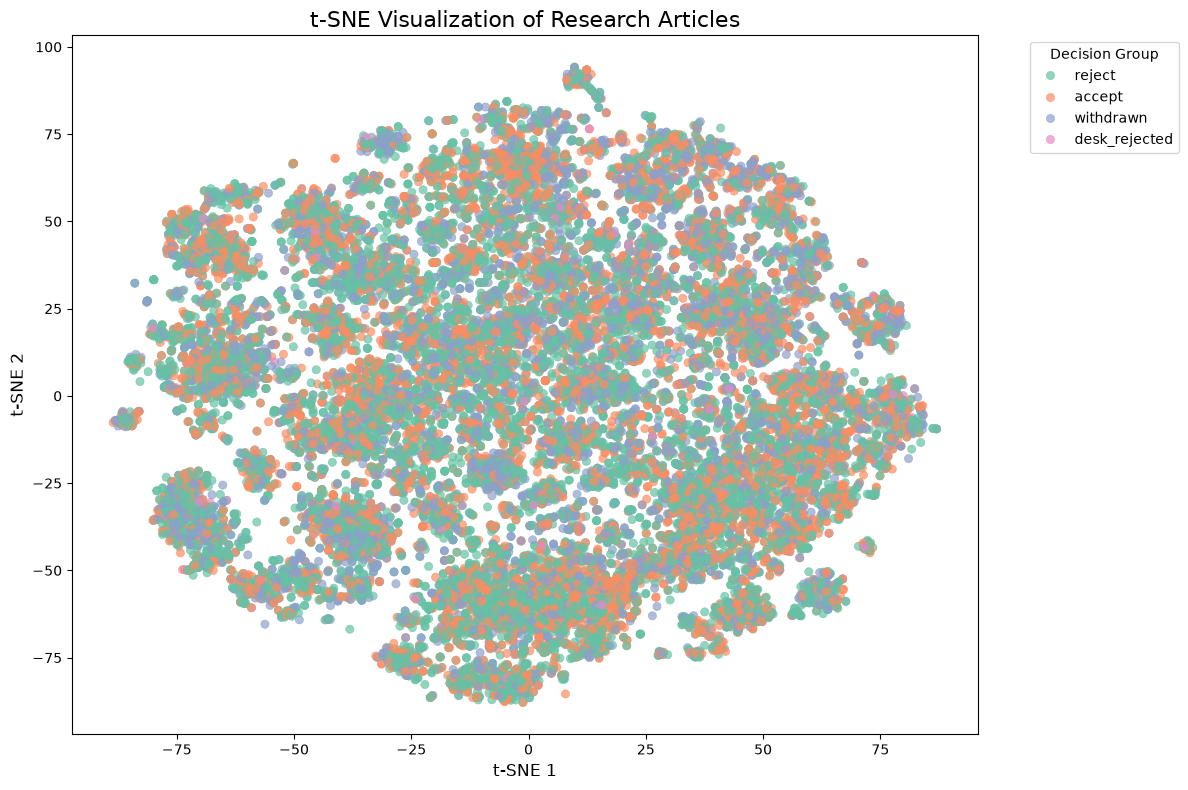

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=papers_tsne,
    x="tsne_1",
    y="tsne_2",
    hue="decision_group",
    palette="Set2",
    s=35,
    alpha=0.7,
    edgecolor=None
)

plt.title("t-SNE Visualization of Research Articles", fontsize=16)
plt.xlabel("t-SNE 1", fontsize=12)
plt.ylabel("t-SNE 2", fontsize=12)

plt.legend(
    title="Decision Group",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


In [7]:
def plot_author_tsne(
    df,
    author,
    author_col="authors",
    x_col="tsne_1",
    y_col="tsne_2",
    title_col="title",
    figsize=(12, 8),
    highlight_color="crimson",
    show_titles=False,
):
    """
    Plots all articles in grey and highlights articles
    written by a selected author.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing article information and t-SNE coordinates.
    author : str
        Author name to search for.
    author_col : str
        Column containing author names.
    x_col, y_col : str
        t-SNE coordinate columns.
    title_col : str
        Column containing article titles.
    figsize : tuple
        Figure dimensions.
    highlight_color : str
        Color used for selected author's articles.
    show_titles : bool
        Whether to annotate selected articles with their titles.
    """

    # Select articles containing the author name
    mask = df[author_col].apply(
        lambda authors: (
            isinstance(authors, (list, tuple, set))
            and any(author.lower() == str(a).lower() for a in authors)
        ) or (
            isinstance(authors, str)
            and author.lower() in authors.lower()
        )
    )

    author_papers = df[mask]

    if author_papers.empty:
        print(f"No articles found for author: {author}")
        return

    plt.figure(figsize=figsize)

    # Plot all articles
    plt.scatter(
        df[x_col],
        df[y_col],
        color="lightgrey",
        alpha=0.4,
        s=25,
        label="Other articles"
    )

    # Highlight selected author's articles
    plt.scatter(
        author_papers[x_col],
        author_papers[y_col],
        color=highlight_color,
        alpha=0.9,
        s=65,
        edgecolor="black",
        linewidth=0.5,
        label=f"{author} ({len(author_papers)} articles)"
    )

    # Optionally annotate article titles
    if show_titles:
        for _, row in author_papers.iterrows():
            plt.annotate(
                str(row[title_col]),
                (row[x_col], row[y_col]),
                fontsize=8,
                alpha=0.8
            )

    plt.title(f"Research articles by {author}", fontsize=15)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return author_papers


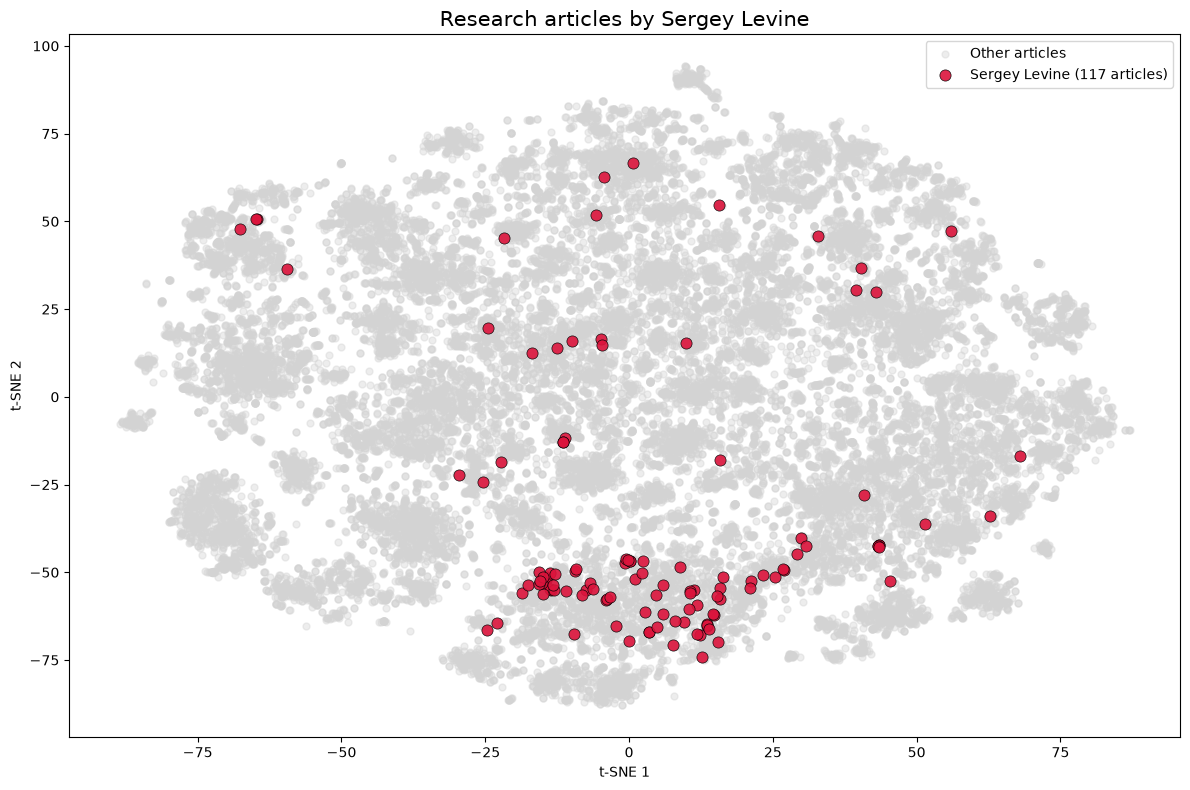

In [8]:
author_papers = plot_author_tsne(
    df=papers_tsne,
    author="Sergey Levine", # Does not filter for the last author, just author contributions
    show_titles=False
)